In [1]:
# 1. Importación y carga de datos: utilidades de scikit-learn (train_test_split, KFold, cross_val_score, ColumnTransformer, Pipeline, LinearRegression, RandomForestRegressor, métricas de regresión, StandardScaler, OneHotEncoder) y se suprimen advertencias con warnings.filterwarnings('ignore')
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split, KFold, cross_val_score # type: ignore
from sklearn.compose import ColumnTransformer # type: ignore
from sklearn.pipeline import Pipeline # type: ignore
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder,  PolynomialFeatures
from sklearn.linear_model import LinearRegression # type: ignore
from sklearn.ensemble import RandomForestRegressor # type: ignore
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error # type: ignore

import warnings

warnings.filterwarnings('ignore')

In [2]:
# 2. Cargamos los datos
data = pd.read_csv('../Data/insurance.csv')
# Comprobamos que tenemos acceso al documento visualizando una muestra
print("Dimensiones:", data.shape)
# Hacemos un estudio de los valores nulos
print("Nulos por columna:\n", data.isnull().sum())
display(data.head())

Dimensiones: (1338, 7)
Nulos por columna:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


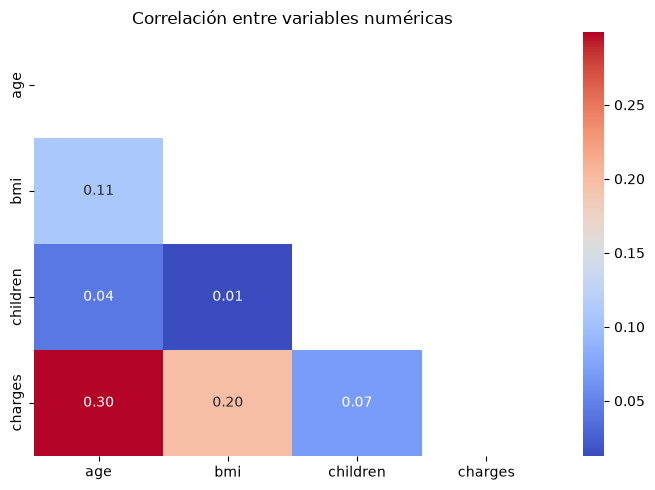

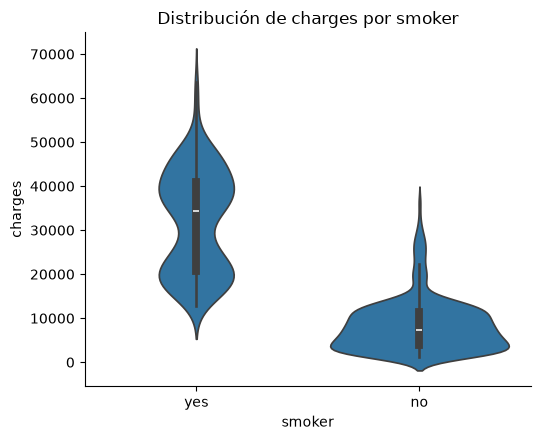

In [3]:
# 3. Correlación numérica
num_df = data.select_dtypes(include="number")
corr = num_df.corr()
mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True

plt.figure(figsize=(7, 5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlación entre variables numéricas")
plt.tight_layout()
plt.show()

# Distribución de charges según smoker
sns.catplot(data=data, x="smoker", y="charges", kind="violin", height=4.5, aspect=1.2)
plt.title("Distribución de charges por smoker")
plt.tight_layout()
plt.show()

In [4]:
# 4. Separación de variables y división train/test
cat_cols = ["sex", "smoker", "region"]
num_cols = ["age", "bmi", "children"]
target_col = "charges"

X = data[cat_cols + num_cols].copy()
y = data['charges'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [5]:
# 5. Pipeline para modelo lineal 
preprocessor_linear = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols), #handle_unknown="ignore": Evita errores si en validación, test o una interfaz de entrada llega una categoría inesperada y drop="first" en LinearRegression: Reduce la redundancia entre columnas binarias generadas por OneHotEncoder al ajustar coeficientes lineales.
        ("num", StandardScaler(), num_cols),
    ]
)

pipe_linear = Pipeline(
    steps=[
        ("prep", preprocessor_linear),
        ("model", LinearRegression()),
    ]
)
pipe_poly = Pipeline([
        ("prep", preprocessor_linear),
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("model", LinearRegression()),
    ])       
pipe_rf = Pipeline([
        ("prep", preprocessor_linear),
        ("model", RandomForestRegressor(random_state=42)),
    ]
)

In [6]:
# 6. Validación cruzada
cv = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "LinearRegression": pipe_linear,
    "PolynomialRegression": pipe_poly,
    "RandomForest": pipe_rf,
}

for nombre, pipe in models.items():
    r2_cv = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="r2")
    mae_cv = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error")
    print(
        f"{nombre:>20} | R2 CV: {r2_cv.mean():.4f} ± {r2_cv.std():.4f} | "
        f"MAE CV: {-mae_cv.mean():.2f} ± {(-mae_cv).std():.2f}"
    )
    mae_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='neg_mean_absolute_error')
    print(
        f"                | R2 CV:                .4    ±             .4   "
        f"| MAE CV:                .2   "
    )

    LinearRegression | R2 CV: 0.7389 ± 0.0311 | MAE CV: 4234.98 ± 248.01
                | R2 CV:                .4    ±             .4   | MAE CV:                .2   
PolynomialRegression | R2 CV: 0.8331 ± 0.0301 | MAE CV: 2987.48 ± 187.06
                | R2 CV:                .4    ±             .4   | MAE CV:                .2   
        RandomForest | R2 CV: 0.8295 ± 0.0253 | MAE CV: 2802.44 ± 164.35
                | R2 CV:                .4    ±             .4   | MAE CV:                .2   


In [7]:
# 7. Entrenamiento y predicción
predicciones = {}
filas_metricas = []

for nombre, pipe in models.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    predicciones[nombre] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    filas_metricas.append({
        "Modelo": nombre,
        "MAE": round(mae, 2),
        "MSE": round(mse, 2),
        "RMSE": round(rmse, 2),
        "R2": round(r2, 4),
    })

df_metricas = pd.DataFrame(filas_metricas)
display(df_metricas)

,Modelo,MAE,MSE,RMSE,R2
0,LinearRegression,4181.19,33596915.85,5796.28,0.7836
1,PolynomialRegression,2729.50,20712805.99,4551.13,0.8666
2,RandomForest,2541.72,20879971.69,4569.46,0.8655


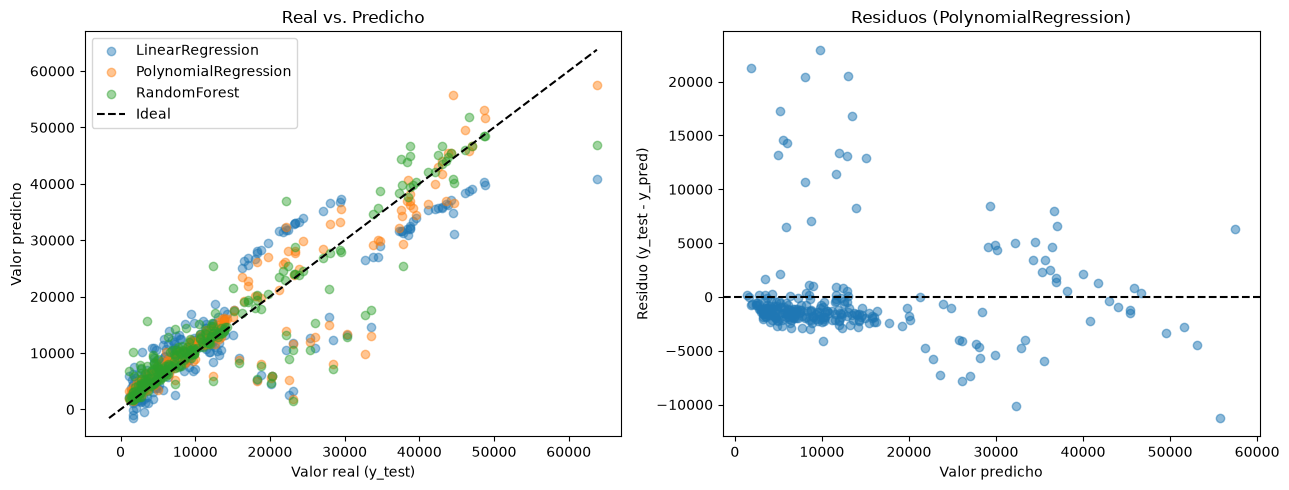

In [8]:
# 8. Visualización de resultados
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for nombre, y_pred in predicciones.items():
    axes[0].scatter(y_test, y_pred, alpha=0.45, label=nombre)

min_val = min(y_test.min(), *(p.min() for p in predicciones.values()))
max_val = max(y_test.max(), *(p.max() for p in predicciones.values()))
axes[0].plot([min_val, max_val], [min_val, max_val], "--", color="black", label="Ideal")
axes[0].set_xlabel("Valor real (y_test)")
axes[0].set_ylabel("Valor predicho")
axes[0].set_title("Real vs. Predicho")
axes[0].legend()

mejor_modelo = df_metricas.sort_values("R2", ascending=False).iloc[0]["Modelo"]
residuos = y_test - predicciones[mejor_modelo]
axes[1].scatter(predicciones[mejor_modelo], residuos, alpha=0.5)
axes[1].axhline(0, linestyle="--", color="black")
axes[1].set_xlabel("Valor predicho")
axes[1].set_ylabel("Residuo (y_test - y_pred)")
axes[1].set_title(f"Residuos ({mejor_modelo})")

plt.tight_layout()
plt.show()